In [34]:
import pandas as pd

df = pd.read_csv('wavelet.csv')

In [35]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,844246.771846,766322.702933,676362.874956,582653.055304,487632.724253,393843.605076,305121.373537,223931.271079,154857.408559,94572.790876,...,93226.921534,153166.942791,222545.054532,303888.999399,391866.465254,486724.818599,582024.721112,676678.812110,766812.986354,0.0
1,851375.348222,774111.417021,683931.984637,589071.573066,493228.136977,398480.843524,308753.153052,226674.010000,156393.591442,95865.394673,...,93312.556147,153424.613589,223178.694361,305063.310803,394014.921374,489715.817570,586245.862100,681382.519576,772321.154907,0.0
2,884561.046834,805462.679879,712995.277572,616338.739829,518113.814785,420973.478929,328356.639683,243127.911778,169764.937039,105944.804686,...,90432.600876,151332.371735,222692.063303,307100.479375,399330.775529,498983.142903,599785.024406,699926.556974,796329.385742,0.0
3,875623.235671,791263.938793,693748.534380,592467.523342,491291.727575,392664.217563,300174.393228,216875.012549,146730.350371,86788.007042,...,108194.982183,172722.918894,246321.839503,331850.274237,423853.145715,521895.203145,620060.792082,716353.006580,807798.021463,0.0
4,862933.383222,782687.639338,689386.984217,592237.854560,493949.114379,397407.064741,306431.404397,223540.773615,153226.074482,92582.391814,...,98969.366795,160784.411899,231720.006889,314865.545939,404502.003237,500760.392064,597458.846946,693382.098300,785308.674817,0.0


In [36]:
df.shape

(4662, 26)

In [37]:
import joblib

save_dir = './models/'

gmm_models = []
for i in range(6):
    model_filename = f'gmm_model_{i}.pkl'
    model_path = save_dir + model_filename
    loaded_gmm_model = joblib.load(model_path)
    gmm_models.append(loaded_gmm_model)

In [38]:
X = df.iloc[:, :-1]

Y = df.iloc[:, -1]

In [39]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, Y, test_size=0.2, random_state=42)

In [40]:
import numpy as np

predicted_probs = np.zeros((len(X_val), 6))
for i in range(6):
    predicted_probs[:, i] = gmm_models[i].score_samples(X_val)

In [41]:
predicted_labels = np.argmax(predicted_probs, axis=1)


In [42]:
def predictionMapping(prediction):
	if prediction == 0 or prediction == 4:
		return 0
	elif prediction == 5:
		return 1
	else:
		return 2

# Night Time

In [26]:
for i in range (len(predicted_labels)):
	predicted_labels[i] = predictionMapping(predicted_labels[i])

y_val = y_val.apply(predictionMapping)

In [28]:
from sklearn import metrics

accuracy = metrics.accuracy_score(predicted_labels, y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.8585209003215434


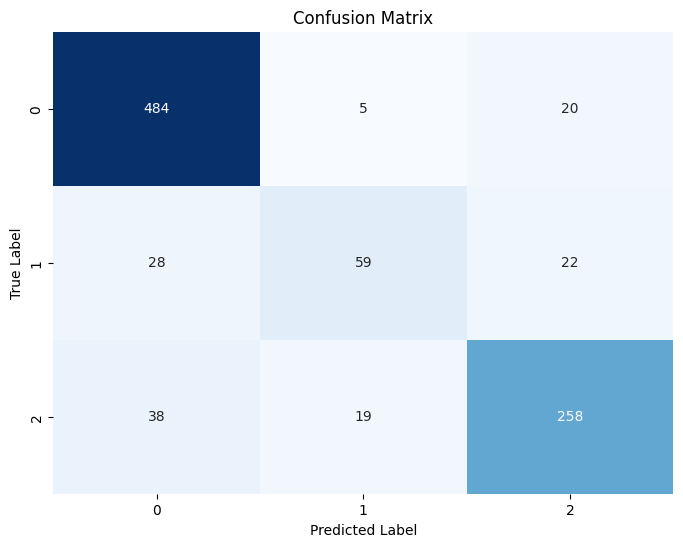

In [30]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(y_val, predicted_labels)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [31]:
from sklearn.metrics import f1_score

f1 = f1_score(y_val, predicted_labels, average='weighted')
print(f"F1 Score: {f1:.4f}")

F1 Score: 0.8537


In [33]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(y_val, predicted_labels, average=None)
recall = recall_score(y_val, predicted_labels, average=None)
f1 = f1_score(y_val, predicted_labels, average=None)

# Print results for each class
for class_label in range(3):
    print(f"Class {class_label}:")
    print(f"Precision: {precision[class_label]:.4f}")
    print(f"Recall: {recall[class_label]:.4f}")
    print(f"F1 Score: {f1[class_label]:.4f}\n")


Class 0:
Precision: 0.8800
Recall: 0.9509
F1 Score: 0.9141

Class 1:
Precision: 0.7108
Recall: 0.5413
F1 Score: 0.6146

Class 2:
Precision: 0.8600
Recall: 0.8190
F1 Score: 0.8390



# Day Time 

Run only upper part

In [43]:
night_y_val = []
night_y_pred = []

for i in range (len(predicted_labels)):
	if y_val.iloc[i] != 5:
		night_y_val.append(predictionMapping(y_val.iloc[i]))
		if predicted_labels[i] == 5:
			night_y_pred.append(predictionMapping(0))
		else:
			night_y_pred.append(predictionMapping(predicted_labels[i]))





In [44]:
from sklearn import metrics

accuracy = metrics.accuracy_score(night_y_pred, night_y_val)
print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.9065533980582524


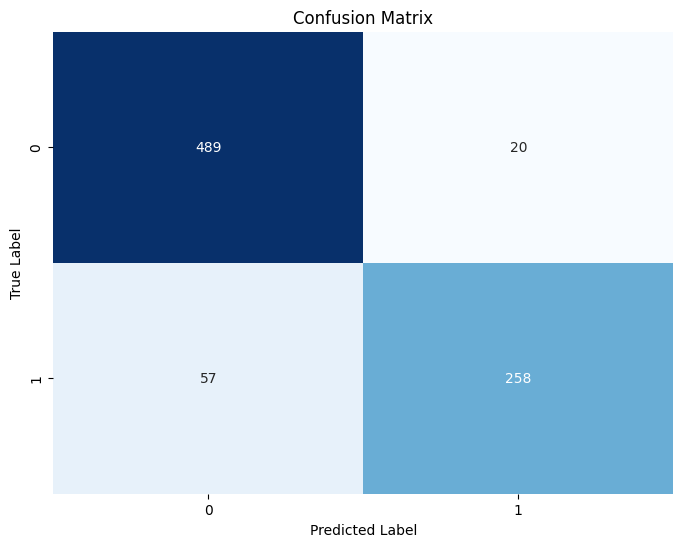

In [45]:
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
import seaborn as sns

# Generate the confusion matrix
cm = confusion_matrix(night_y_val, night_y_pred)

# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [46]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Assuming you have true labels (y_actual) and predicted labels (y_pred)
# For each class (0, 1, 2, 3), calculate precision, recall, and F1 score
precision = precision_score(night_y_val, night_y_pred, average=None)
recall = recall_score(night_y_val, night_y_pred, average=None)
f1 = f1_score(night_y_val, night_y_pred, average=None)

# Print results for each class
for class_label in range(2):
    print(f"Class {class_label}:")
    print(f"Precision: {precision[class_label]:.4f}")
    print(f"Recall: {recall[class_label]:.4f}")
    print(f"F1 Score: {f1[class_label]:.4f}\n")


Class 0:
Precision: 0.8956
Recall: 0.9607
F1 Score: 0.9270

Class 1:
Precision: 0.9281
Recall: 0.8190
F1 Score: 0.8702

